In [1]:

# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load the generated MFCC CSV
df = pd.read_csv("/content/MFCC_Gender_Features.csv")

# Separate features and labels
X = df.drop(columns=["Filename", "Class"])
y = df["Class"].astype(int)

# Display dataset information
print("Dataset Shape:", df.shape)
print("Feature Shape:", X.shape)
print("Label Shape:", y.shape)

# Display class distribution
print("\nClass Distribution:")
print(y.value_counts().sort_index())

# Display class percentages
print("\nClass Percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

# Check missing and infinite values
print("\nMissing Values:", X.isnull().sum().sum())
print("Infinite Values:", np.isinf(X.to_numpy()).sum())

# Check unique labels
print("\nUnique Class Labels:", sorted(y.unique()))


Dataset Shape: (143, 28)
Feature Shape: (143, 26)
Label Shape: (143,)

Class Distribution:
Class
1    124
2     19
Name: count, dtype: int64

Class Percentages:
Class
1    86.71
2    13.29
Name: proportion, dtype: float64

Missing Values: 0
Infinite Values: 0

Unique Class Labels: [np.int64(1), np.int64(2)]


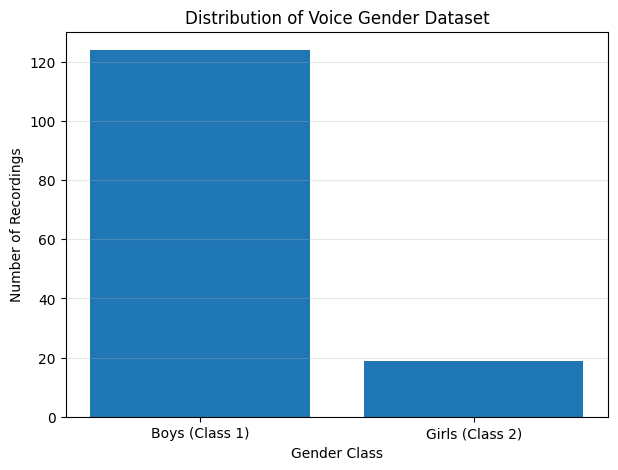

In [3]:

# Plot class distribution
class_counts = y.value_counts().sort_index()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Boys (Class 1)", "Girls (Class 2)"],
    [class_counts.get(1, 0), class_counts.get(2, 0)]
)

plt.title("Distribution of Voice Gender Dataset")
plt.xlabel("Gender Class")
plt.ylabel("Number of Recordings")
plt.grid(axis="y", alpha=0.3)

plt.show()


In [4]:

# Check whether both classes have sufficient samples
assert set(y.unique()) == {1, 2}, "Expected labels 1 (Boys) and 2 (Girls)"

assert not X.isnull().any().any(), "Missing values found in features!"

assert np.isfinite(X.to_numpy()).all(), "Infinite values found!"

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display training and testing distribution
print("TRAINING DATA")
print("Total Samples:", len(X_train))
print(y_train.value_counts().sort_index())

print("\nTESTING DATA")
print("Total Samples:", len(X_test))
print(y_test.value_counts().sort_index())


TRAINING DATA
Total Samples: 114
Class
1    99
2    15
Name: count, dtype: int64

TESTING DATA
Total Samples: 29
Class
1    25
2     4
Name: count, dtype: int64


In [5]:

# SVM pipeline
svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=42
    ))
])

# Random Forest pipeline
rf_pipeline = Pipeline([
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42
    ))
])

print("Both improved models initialized!")


Both improved models initialized!


In [6]:

# Set number of folds based on minority class size
min_class_samples = y_train.value_counts().min()
n_splits = min(5, min_class_samples)

if n_splits < 2:
    raise ValueError("Not enough minority-class samples for cross-validation.")

# Stratified cross-validation
cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=42
)

print("Number of CV Folds:", n_splits)

# SVM parameter combinations
svm_params = {
    "classifier__C": [0.1, 1, 10, 100],
    "classifier__gamma": ["scale", 0.001, 0.01, 0.1, 1]
}

# Random Forest parameter combinations
rf_params = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [None, 5, 10, 15],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2, 4]
}

print("Hyperparameter grids prepared!")


Number of CV Folds: 5
Hyperparameter grids prepared!


In [7]:

# Tune SVM
svm_search = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=svm_params,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

svm_search.fit(X_train, y_train)

# Tune Random Forest
rf_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True
)

rf_search.fit(X_train, y_train)

# Display best parameters
print("SVM Best Parameters:")
print(svm_search.best_params_)

print("\nSVM Best CV Macro F1:")
print(round(svm_search.best_score_, 4))

print("\nRandom Forest Best Parameters:")
print(rf_search.best_params_)

print("\nRandom Forest Best CV Macro F1:")
print(round(rf_search.best_score_, 4))


SVM Best Parameters:
{'classifier__C': 10, 'classifier__gamma': 0.01}

SVM Best CV Macro F1:
0.7374

Random Forest Best Parameters:
{'classifier__max_depth': None, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}

Random Forest Best CV Macro F1:
0.5692


In [8]:

# Get best models
svm_best = svm_search.best_estimator_
rf_best = rf_search.best_estimator_

# Generate test predictions
svm_pred = svm_best.predict(X_test)
rf_pred = rf_best.predict(X_test)

# Evaluation function
def evaluate_model(y_true, y_pred, name, cv_score):

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "Precision (Macro)": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "F1 (Macro)": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "CV Macro F1": cv_score
    }

# Compare both models
results = pd.DataFrame([
    evaluate_model(
        y_test, svm_pred, "SVM (RBF)", svm_search.best_score_
    ),
    evaluate_model(
        y_test, rf_pred, "Random Forest", rf_search.best_score_
    )
])

print("MODEL PERFORMANCE COMPARISON")
display(results.round(4))


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Balanced Accuracy,Precision (Macro),Recall (Macro),F1 (Macro),CV Macro F1
0,SVM (RBF),0.8276,0.69,0.6583,0.69,0.6712,0.7374
1,Random Forest,0.8621,0.50,0.4310,0.50,0.4630,0.5692


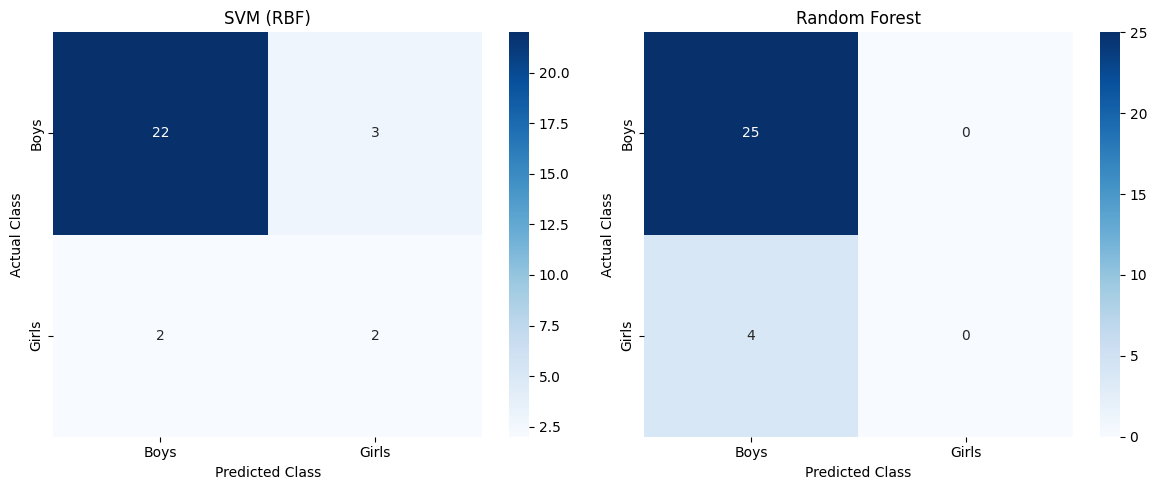

In [9]:

# Create confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("SVM (RBF)", svm_pred),
    ("Random Forest", rf_pred)
]

for ax, (name, predictions) in zip(axes, models):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[1, 2]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Boys", "Girls"],
        yticklabels=["Boys", "Girls"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()


In [10]:

# SVM report
print("SVM CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    svm_pred,
    labels=[1, 2],
    target_names=["Boys", "Girls"],
    zero_division=0
))

# Random Forest report
print("\nRANDOM FOREST CLASSIFICATION REPORT")
print(classification_report(
    y_test,
    rf_pred,
    labels=[1, 2],
    target_names=["Boys", "Girls"],
    zero_division=0
))


SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Boys       0.92      0.88      0.90        25
       Girls       0.40      0.50      0.44         4

    accuracy                           0.83        29
   macro avg       0.66      0.69      0.67        29
weighted avg       0.85      0.83      0.84        29


RANDOM FOREST CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Boys       0.86      1.00      0.93        25
       Girls       0.00      0.00      0.00         4

    accuracy                           0.86        29
   macro avg       0.43      0.50      0.46        29
weighted avg       0.74      0.86      0.80        29



In [11]:

# Compare cross-validation performance
if svm_search.best_score_ >= rf_search.best_score_:
    best_model = svm_best
    best_name = "SVM (RBF)"
    best_predictions = svm_pred
else:
    best_model = rf_best
    best_name = "Random Forest"
    best_predictions = rf_pred

print("SELECTED MODEL:", best_name)

print("\nTest Accuracy:",
      round(accuracy_score(y_test, best_predictions) * 100, 2), "%")

print("Test Balanced Accuracy:",
      round(balanced_accuracy_score(y_test, best_predictions), 4))

print("Test Macro F1:",
      round(f1_score(
          y_test, best_predictions,
          average="macro"
      ), 4))

print("\nSelected Model Classification Report:")

print(classification_report(
    y_test,
    best_predictions,
    labels=[1, 2],
    target_names=["Boys", "Girls"],
    zero_division=0
))


SELECTED MODEL: SVM (RBF)

Test Accuracy: 82.76 %
Test Balanced Accuracy: 0.69
Test Macro F1: 0.6712

Selected Model Classification Report:
              precision    recall  f1-score   support

        Boys       0.92      0.88      0.90        25
       Girls       0.40      0.50      0.44         4

    accuracy                           0.83        29
   macro avg       0.66      0.69      0.67        29
weighted avg       0.85      0.83      0.84        29



In [12]:
from sklearn.base import clone
from google.colab import files

# Create a fresh copy of the selected model
final_model = clone(best_model)

# Train on the complete dataset
final_model.fit(X, y)

# Save the complete pipeline
model_path = "/content/Final_Gender_Classification_Model.pkl"

joblib.dump(final_model, model_path)

print("Final model trained and saved!")
print("Selected Model:", best_name)
print("Model Path:", model_path)

# Download trained model
files.download(model_path)

Final model trained and saved!
Selected Model: SVM (RBF)
Model Path: /content/Final_Gender_Classification_Model.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

SENSITIVITY (RECALL)
-------------------
Boys Sensitivity: 0.8800
Girls Sensitivity: 0.5000


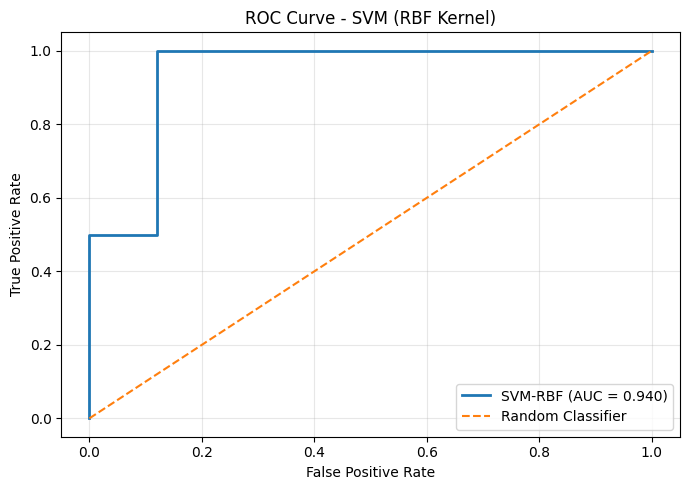


ROC AUC Score: 0.9400


In [14]:
from sklearn.metrics import (
    recall_score,
    roc_curve,
    roc_auc_score,
    classification_report
)
import matplotlib.pyplot as plt

# -----------------------------------
# 1. Sensitivity (Recall)
# -----------------------------------

# Class 1 = Boys, Class 2 = Girls
sensitivity_boys = recall_score(
    y_test, svm_pred, pos_label=1
)

sensitivity_girls = recall_score(
    y_test, svm_pred, pos_label=2
)

print("SENSITIVITY (RECALL)")
print("-------------------")
print(f"Boys Sensitivity: {sensitivity_boys:.4f}")
print(f"Girls Sensitivity: {sensitivity_girls:.4f}")

# -----------------------------------
# 2. ROC Curve
# -----------------------------------

# Obtain decision scores from the trained best model (SVM pipeline handles scaling automatically)
y_scores = best_model.decision_function(X_test)

# Convert labels: Boys = 0, Girls = 1 (mapping Class 2 to 1 and Class 1 to 0)
y_test_binary = (y_test == 2).astype(int)

# Calculate ROC values
fpr, tpr, thresholds = roc_curve(
    y_test_binary, y_scores
)

# Calculate AUC
auc_score = roc_auc_score(
    y_test_binary, y_scores
)

# -----------------------------------
# 3. Plot ROC Curve
# -----------------------------------

plt.figure(figsize=(7, 5))

plt.plot(
    fpr, tpr,
    label=f"SVM-RBF (AUC = {auc_score:.3f})",
    linewidth=2
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - SVM (RBF Kernel)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nROC AUC Score: {auc_score:.4f}")